# Laboratorium 1 – Uczenie maszynowe


## Cel ćwiczenia

Celem niniejszego laboratorium jest przetwarzanie danych na potrzeby zbudowania modeli uczenia maszynowego. Pracujemy na zbiorze **"Polish companies bankruptcy"**, który zawiera dane finansowe polskich spółek, dane te wymagają obróbki przed budową modelu klasyfikacji.

### Zagadnienia opracowywane w zadaniu:
- **Redukcja wymiarów** – PCA (Principal Component Analysis) oraz t-SNE (t-distributed Stochastic Neighbor Embedding)
- **Transformacje danych** – standaryzacja i normalizacja
- **Czyszczenie danych** – obsługa brakujących wartości, outliery
- **Modele klasyfikacji** – dwa wybrane algorytmy uczenia maszynowego (Random Forest i Logisitic Regression)

### Opis zbioru danych:
Zbiór składa się z 5 plików (jeden na rok analizy), opisanych 64 atrybutami dotyczącymi analizy polskich spółek. Celem klasyfikacji jest przewidzenie, czy dana spółka zbankrutuje (klasa = 1) czy nie (klasa = 0).
Dane zawierają:
- Wyłącznie atrybuty numeryczne (wskaźniki finansowe)
- Rekordy z brakującymi wartościami (`NaN`)
- Wartości ujemne
- Atrybuty o różnych skalach i domenach

## Import bibliotek i pobranie danych


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

sns.set_theme(style='darkgrid', palette='colorblind')
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# Wczytanie danych z pliku
def load_arff(filepath: str) -> pd.DataFrame:
    """Wczytuje plik .arff i zwraca go jako DataFrame."""
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(da# Wczytanie danych z pliku
def load_arff(filepath: str) -> pd.DataFrame:
    """Wczytuje plik .arff i zwraca go jako DataFrame."""
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    df['class'] = df['class'].str.decode('utf-8').astype(int)
    return df

files = [
    '1year.arff',
    '2year.arff',
    '3year.arff',
    '4year.arff',
    '5year.arff'
]

dfs = []
for f in files:
    df_tmp = load_arff(f'polish_companies_bankruptcy_data/{f}')
    dfs.append(df_tmp)

df = pd.concat(dfs, ignore_index=True)ta)
    df['class'] = df['class'].str.decode('utf-8').astype(int)
    return df

files = [
    '1year.arff',
    '2year.arff',
    '3year.arff',
    '4year.arff',
    '5year.arff'
]

dfs = []
for f in files:
    df_tmp = load_arff(f'polish_companies_bankruptcy_data/{f}')
    dfs.append(df_tmp)

df = pd.concat(dfs, ignore_index=True)

print(df.shape)

print(f'Wczytano zbiór danych: {df.shape[0]} rekordów, {df.shape[1]} kolumn')
print(f'Kolumny: {list(df.columns[:5])} ... \'class\'')

(43405, 65)
Wczytano zbiór danych: 43405 rekordów, 65 kolumn
Kolumny: ['Attr1', 'Attr2', 'Attr3', 'Attr4', 'Attr5'] ... 'class'


## Zadanie 1 – Badanie cech zbioru wraz z wizualizacją (2 pkt)

In [3]:
# 1.1 Podstawowe informacje o zbiorze danych

print(f'Liczba rekordów:   {df.shape[0]}')
print(f'Liczba atrybutów:  {df.shape[1] - 1}  (+ 1 kolumna klasy)')

print('\nTypy danych')
print(df.dtypes.value_counts())

print('\nPierwsze 5 wierszy')
df.head()

Liczba rekordów:   43405
Liczba atrybutów:  64  (+ 1 kolumna klasy)

Typy danych
float64    64
int64       1
Name: count, dtype: int64

Pierwsze 5 wierszy


,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.200550,0.37951,0.39641,2.0472,32.3510,0.38825,0.249760,1.33050,1.1389,0.50494,...,0.121960,0.39718,0.87804,0.001924,8.4160,5.1372,82.658,4.4158,7.4277,0
1,0.209120,0.49988,0.47225,1.9447,14.7860,0.00000,0.258340,0.99601,1.6996,0.49788,...,0.121300,0.42002,0.85300,0.000000,4.1486,3.2732,107.350,3.4000,60.9870,0
2,0.248660,0.69592,0.26713,1.5548,-1.1523,0.00000,0.309060,0.43695,1.3090,0.30408,...,0.241140,0.81774,0.76599,0.694840,4.9909,3.9510,134.270,2.7185,5.2078,0
3,0.081483,0.30734,0.45879,2.4928,51.9520,0.14988,0.092704,1.86610,1.0571,0.57353,...,0.054015,0.14207,0.94598,0.000000,4.5746,3.6147,86.435,4.2228,5.5497,0
4,0.187320,0.61323,0.22960,1.4063,-7.3128,0.18732,0.187320,0.63070,1.1559,0.38677,...,0.134850,0.48431,0.86515,0.124440,6.3985,4.3158,127.210,2.8692,7.8980,0


In [6]:
# 1.2 Statystyki opisowe

df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Attr1,43397.0,0.035,2.994,-4.638900e+02,0.003,0.050,0.130,9.428000e+01
Attr2,43397.0,0.590,5.843,-4.308700e+02,0.269,0.472,0.688,4.809600e+02
Attr3,43397.0,0.114,5.439,-4.799600e+02,0.022,0.197,0.403,2.833600e+01
Attr4,43271.0,6.315,295.434,-4.030000e-01,1.050,1.570,2.787,5.343300e+04
Attr5,43316.0,-385.347,61243.026,-1.190300e+07,-49.080,-1.034,50.634,1.250100e+06
...,...,...,...,...,...,...,...,...
Attr61,43303.0,17.033,553.049,-1.265600e+01,4.510,6.636,10.394,1.080000e+05
Attr62,43278.0,1502.328,139266.700,-2.336500e+06,42.144,71.326,117.220,2.501600e+07
Attr63,43271.0,9.343,124.177,-1.543000e+00,3.098,5.088,8.599,2.345400e+04
Attr64,42593.0,72.789,2369.339,-1.067700e+04,2.177,4.282,9.776,2.947700e+05


Liczba kolumn z brakującymi danymi: 64 z 65
Łączna liczba brakujących wartości: 41322

Top 10 kolumn z największą liczbą braków:
        Brakujące  Procent
Attr37      18984    43.74
Attr21       5854    13.49
Attr27       2764     6.37
Attr60       2152     4.96
Attr45       2147     4.95
Attr24        922     2.12
Attr64        812     1.87
Attr53        812     1.87
Attr28        812     1.87
Attr54        812     1.87


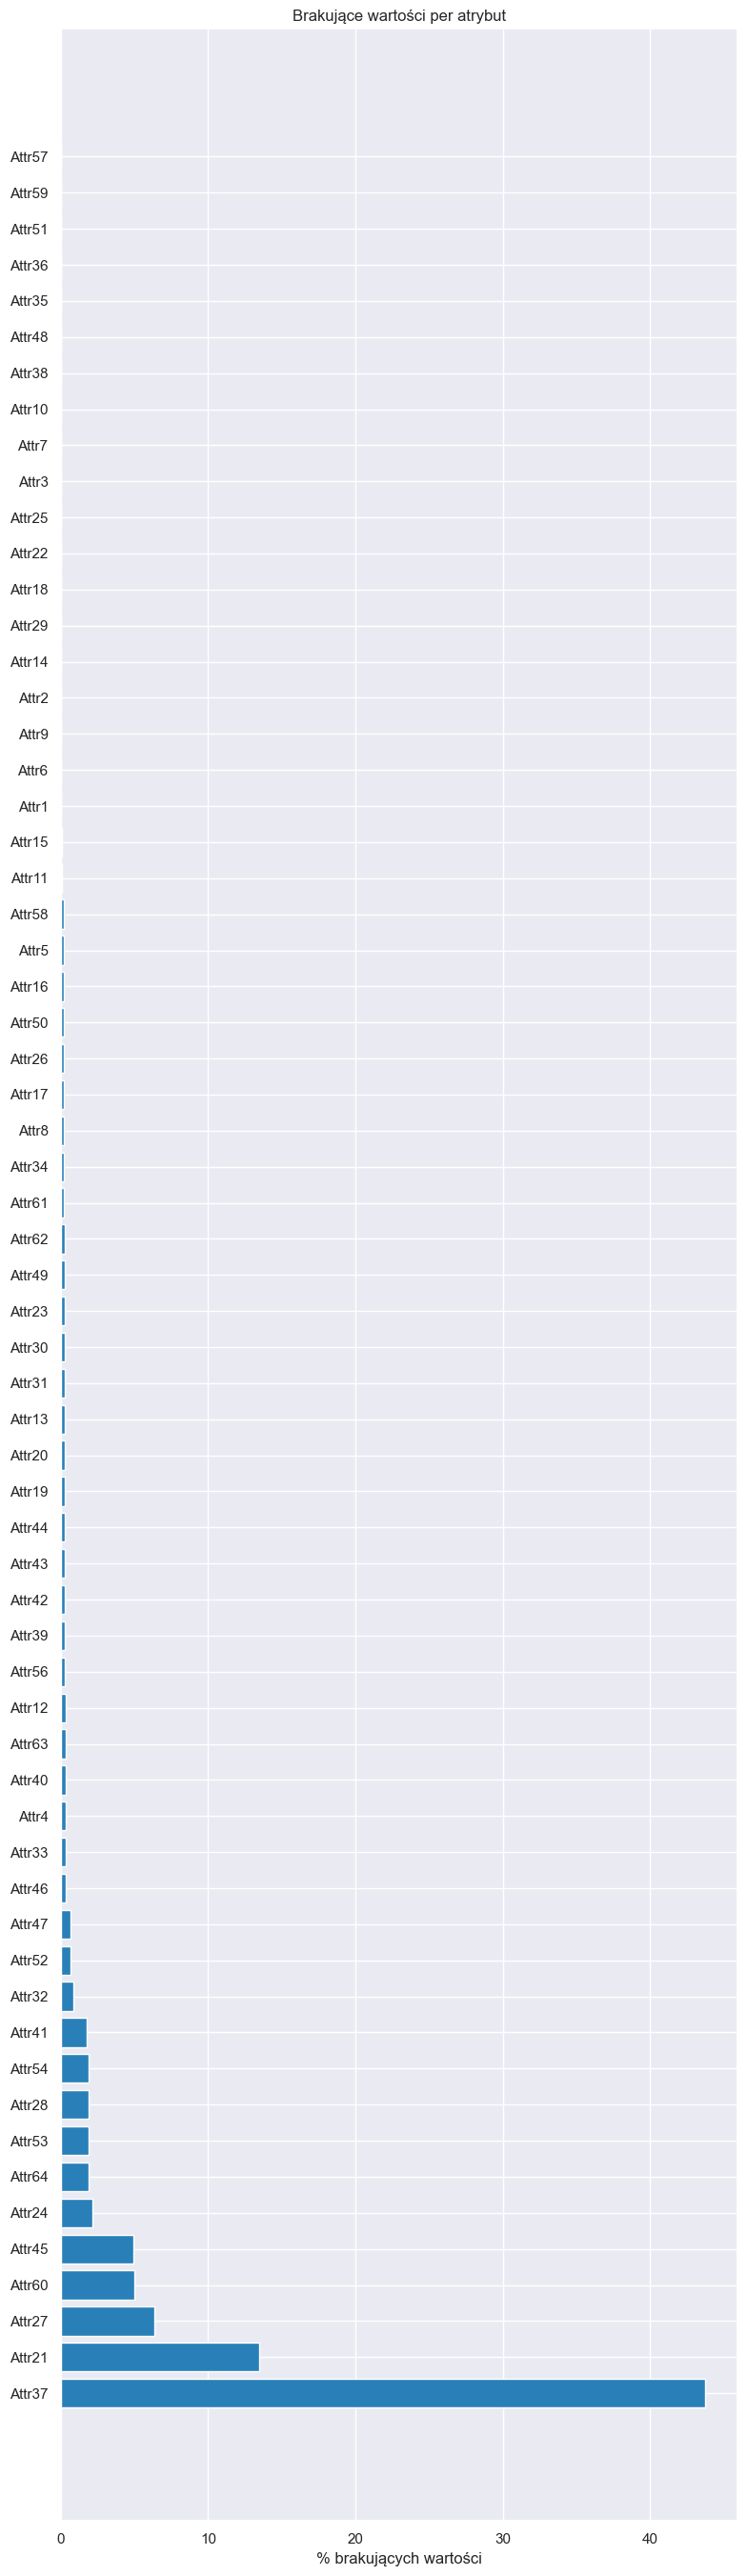


Wniosek: część kolumn zawiera brakujące wartości wymagające obsługi.
Kolumny z niewielką liczbą braków zostaną poddane imputacji medianą,
natomiast kolumny z bardzo wysokim odsetkiem braków mogą zostać usunięte.
Wniosek: wiele kolumn zawiera znaczną liczbę brakujących wartości – wymagane imputowanie.



In [4]:
#1.3 Analiza brakujących wartości

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Brakujące': missing,
    'Procent': missing_pct
}).sort_values('Procent', ascending=False)

print(f'Liczba kolumn z brakującymi danymi: {(missing > 0).sum()} z {df.shape[1]}')
print(f'Łączna liczba brakujących wartości: {missing.sum()}')
print(f'\nTop 10 kolumn z największą liczbą braków:')
print(missing_df.head(10))

missing_df = missing_df[missing_df['Procent'] > 0]

fig, ax = plt.subplots(figsize=(8, len(missing_df) * 0.4 + 2))
ax.barh(missing_df.index, missing_df['Procent'], color='#2980b9')

ax.set_xlabel('% brakujących wartości')
ax.set_title('Brakujące wartości per atrybut')
plt.tight_layout()
plt.show()

summary = """
Wniosek: część kolumn zawiera brakujące wartości wymagające obsługi.
Kolumny z niewielką liczbą braków zostaną poddane imputacji medianą,
natomiast kolumny z bardzo wysokim odsetkiem braków mogą zostać usunięte.
Wniosek: wiele kolumn zawiera znaczną liczbę brakujących wartości – wymagane imputowanie.
"""
print(summary)

Rozkład klas
 Nie bankrutuje (0):  41314  (95.18%)
 Bankrutuje (1):   2091  (4.82%)


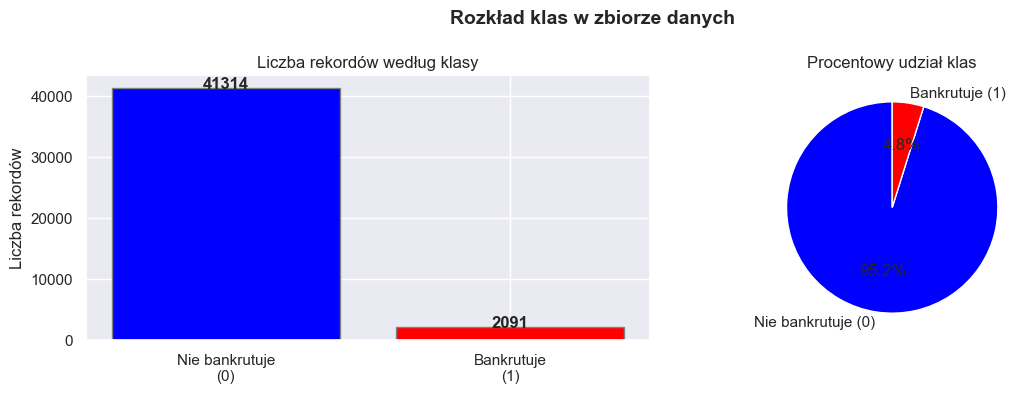


Wniosek: zbiór jest silnie niezbalansowany – klasa 1 (bankructwo) stanowi wyraźną mniejszość.
Niezbalansowanie klas może prowadzić do modeli faworyzujących klasę dominującą (0),
dlatego przy ocenie modeli należy opierać się na metrykach takich jak np. F1-score,
a nie wyłącznie na accuracy.



In [5]:
# 1.4 Rozkład klas
class_counts = df['class'].value_counts().sort_index()
class_pct = df['class'].value_counts(normalize=True).sort_index() * 100

print('Rozkład klas')
for cls in class_counts.index:
    label = 'Bankrutuje (1)' if cls == 1 else 'Nie bankrutuje (0)'
    print(f' {label}: {class_counts[cls]:>6}  ({class_pct[cls]:.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Wykres słupkowy
axes[0].bar(['Nie bankrutuje\n(0)', 'Bankrutuje\n(1)'],
            class_counts.values,
            color=['blue', 'red'], edgecolor='gray')
axes[0].set_title('Liczba rekordów według klasy')
axes[0].set_ylabel('Liczba rekordów')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Wykres kołowy
axes[1].pie(class_counts.values,
            labels=['Nie bankrutuje (0)', 'Bankrutuje (1)'],
            autopct='%1.1f%%', colors=['blue', 'red'],
            startangle=90)
axes[1].set_title('Procentowy udział klas')

plt.suptitle('Rozkład klas w zbiorze danych', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

summary = """
Wniosek: zbiór jest silnie niezbalansowany – klasa 1 (bankructwo) stanowi wyraźną mniejszość.
Niezbalansowanie klas może prowadzić do modeli faworyzujących klasę dominującą (0),
dlatego przy ocenie modeli należy opierać się na metrykach takich jak np. F1-score,
a nie wyłącznie na accuracy.
"""
print(summary)

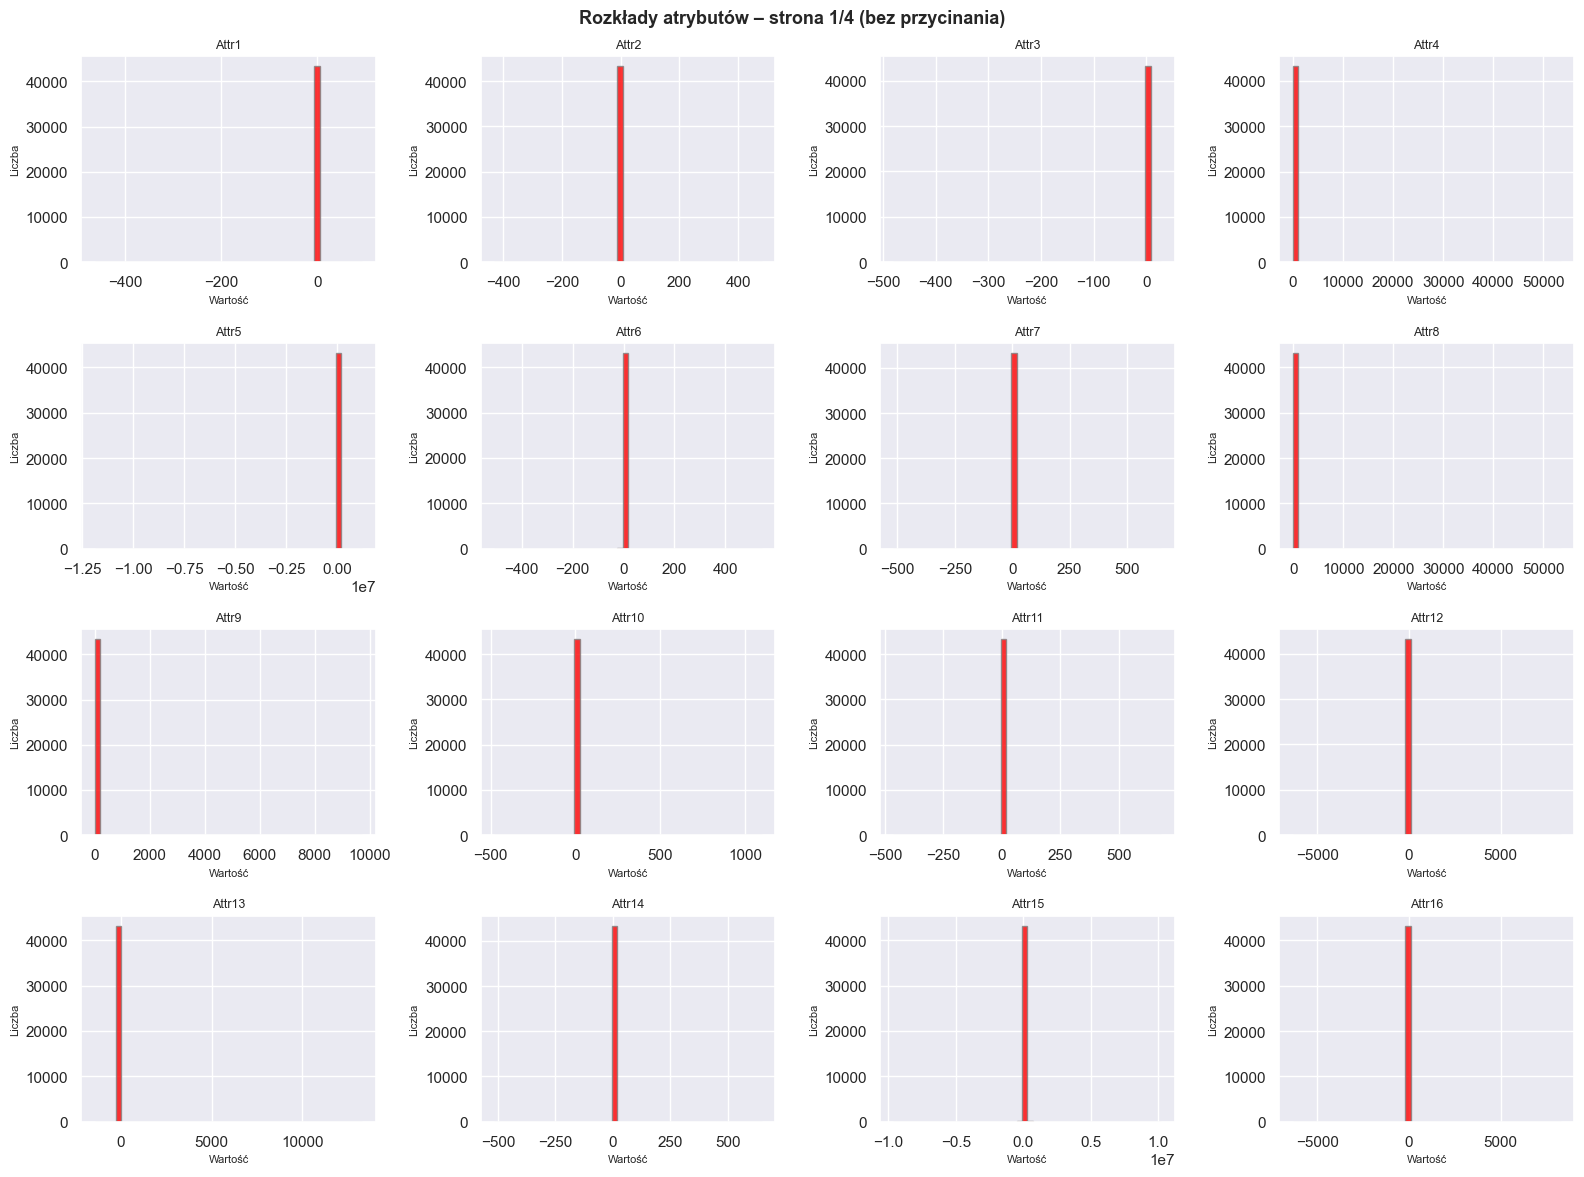

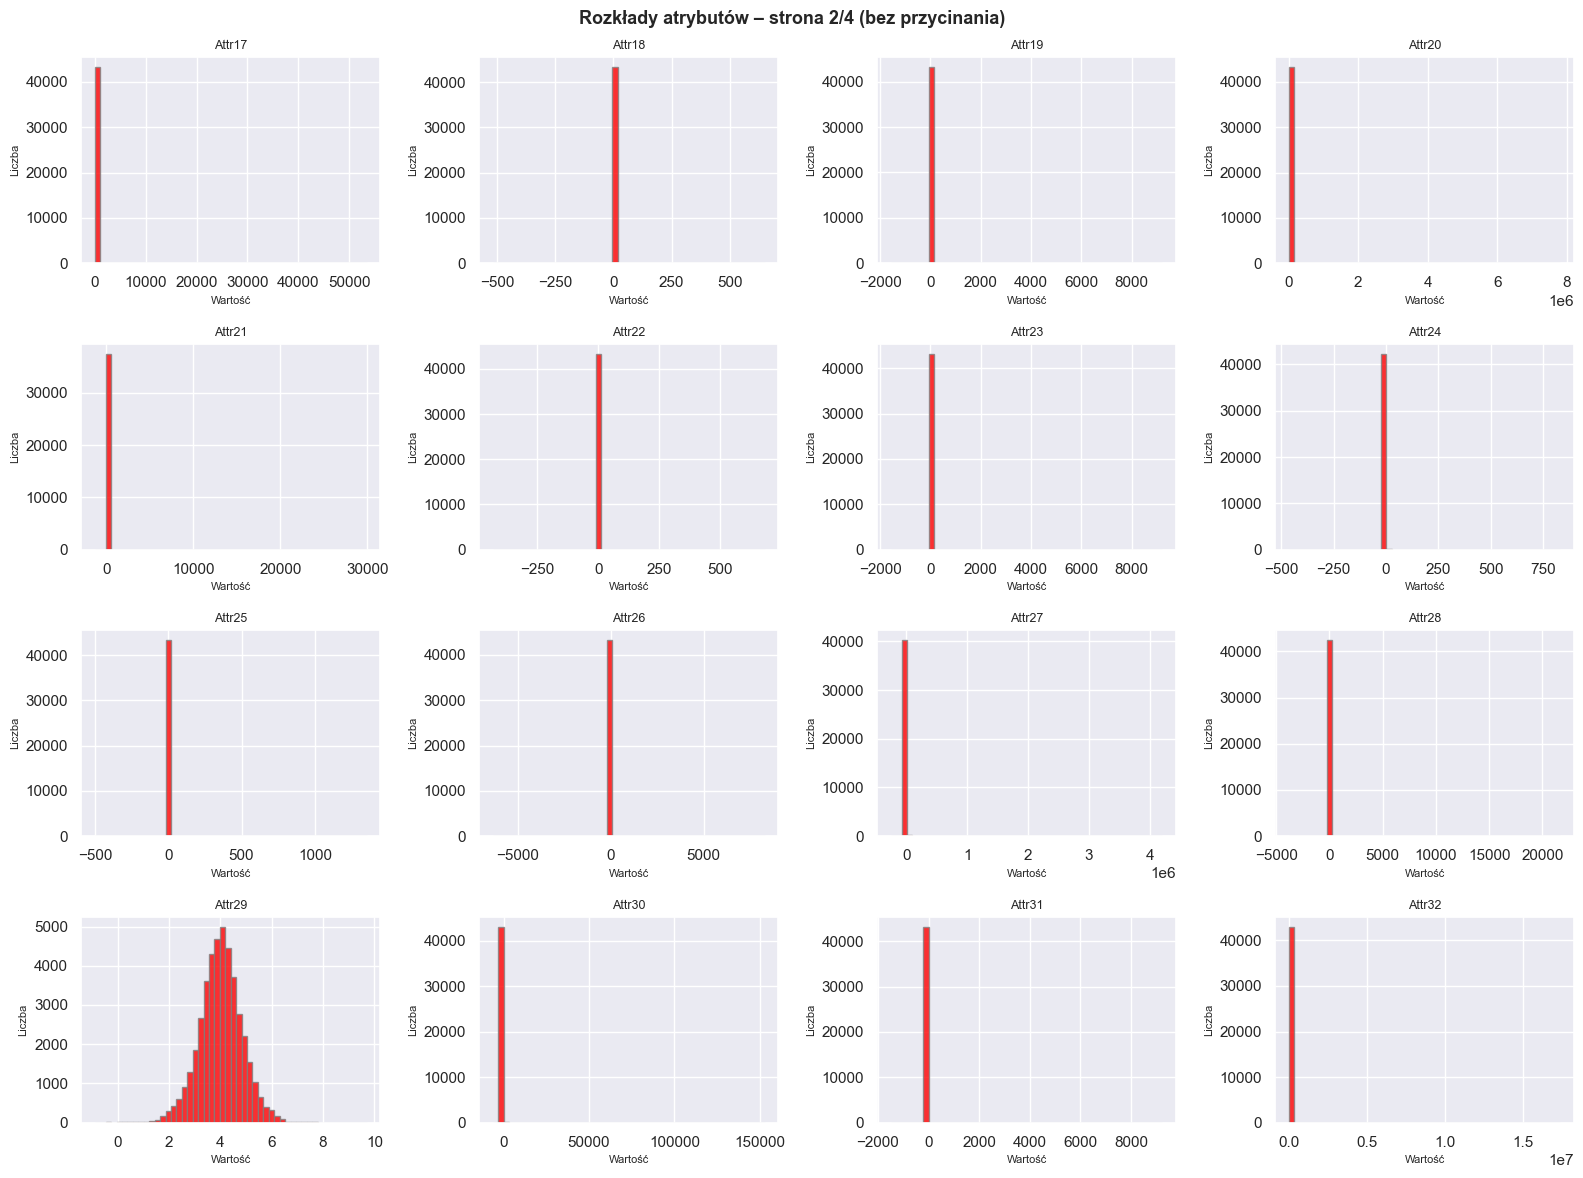

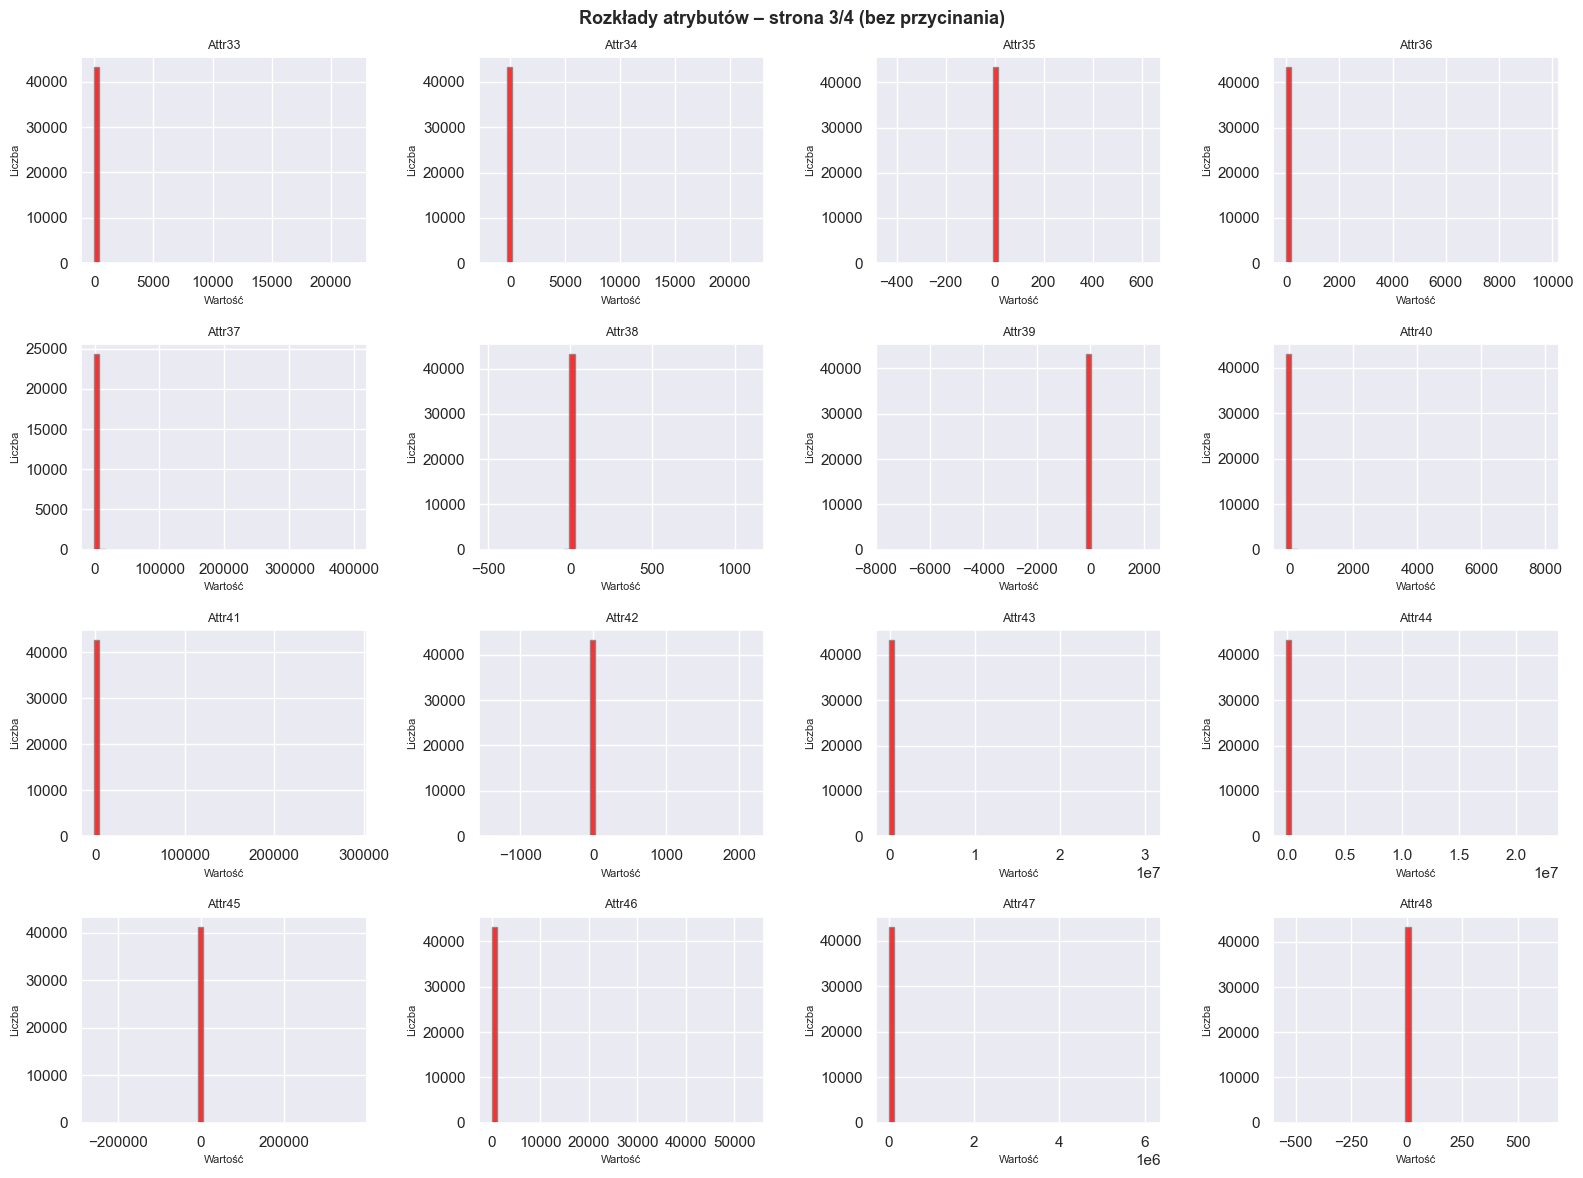

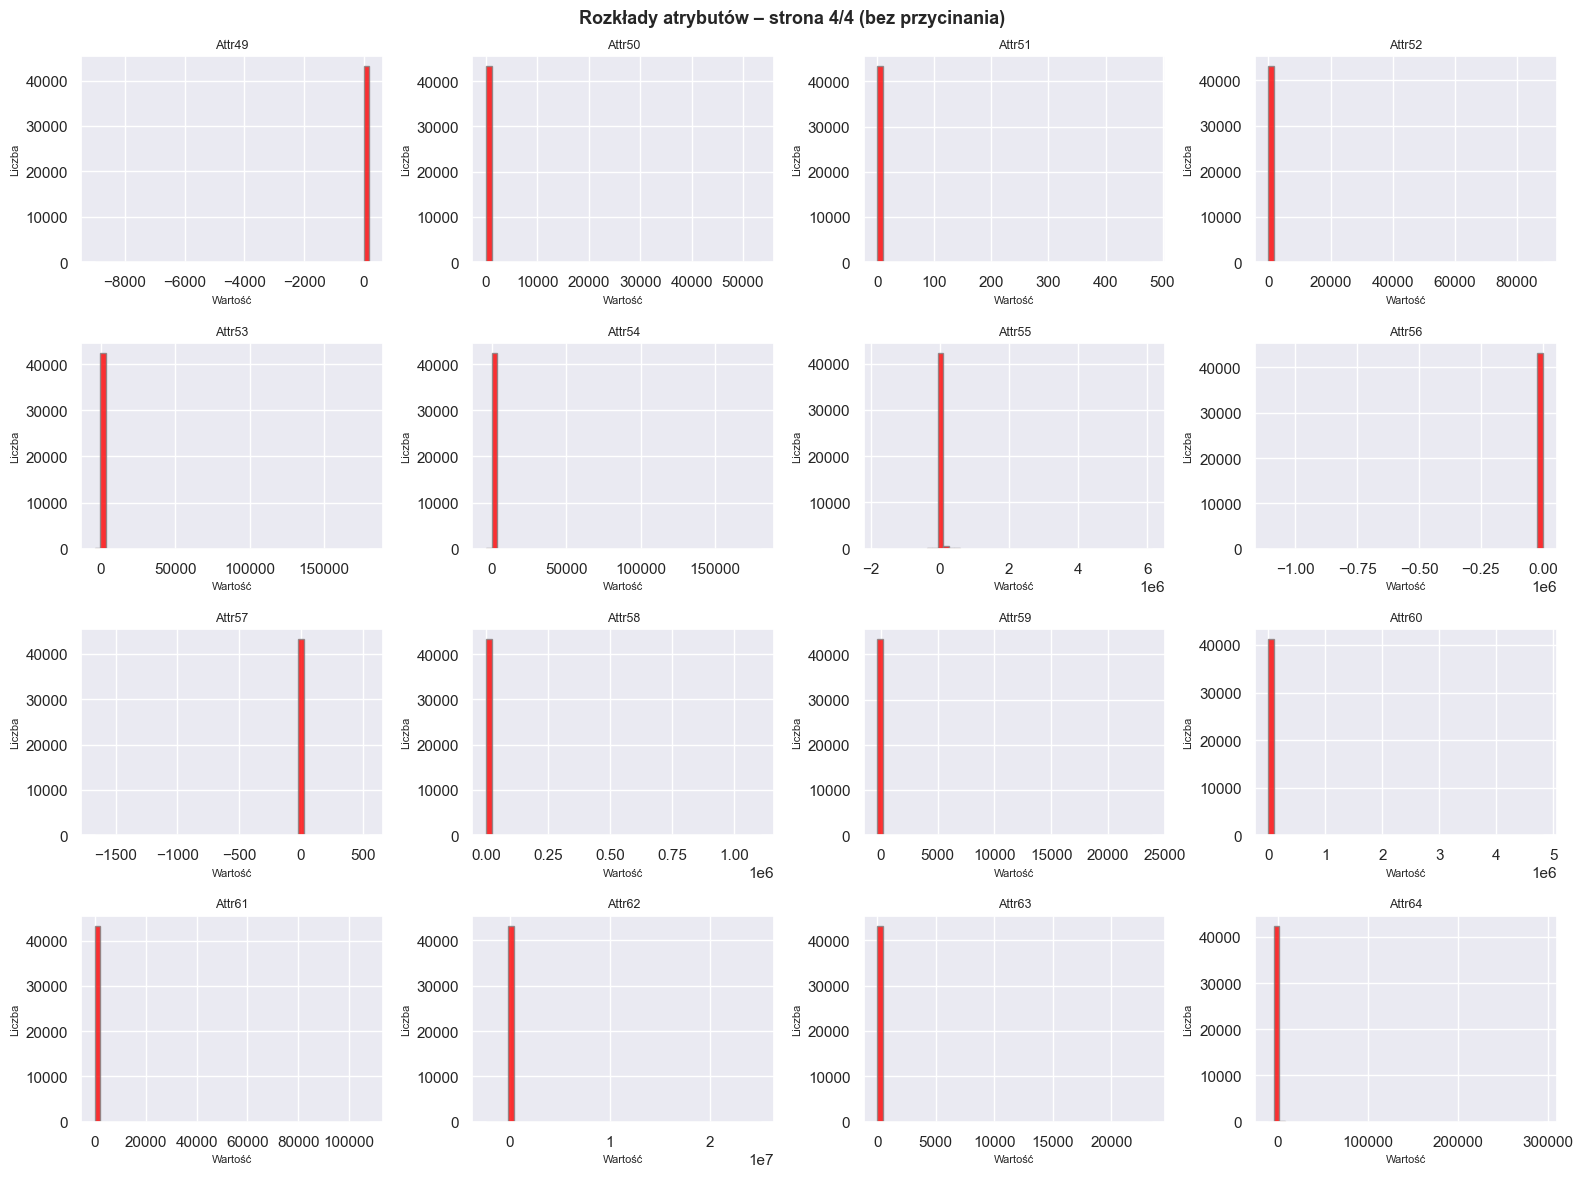


Wniosek: większość atrybutów wykazuje silnie asymetryczny rozkład lewostronny,
spora liczba wykazuje odwrotny rozkład prawostronny. Większość wykresów wychyla się w lewo lub prawo
oraz posiada obecność ekstremalnych wartości odstających, które ściskają większość obserwacji
do wąskiego zakresu na osi X. Potwierdza to konieczność zastosowania RobustScaler
lub transformacji logarytmicznej przed budową modeli.



In [8]:
# 1.5 Rozkłady wszystkich atrybutów numerycznych
features = [col for col in df.columns if col != 'class']

CLIP = False  # True = przycięcie do [1%, 99%], False = pełny rozkład

COLS = 4
ROWS = 4
PER_PAGE = COLS * ROWS  # 16 wykresów na stronę

# Dzielimy wszystkie atrybuty na strony po 16
pages = [features[i:i + PER_PAGE] for i in range(0, len(features), PER_PAGE)]
clip_label = 'przycięte do [1%, 99%]' if CLIP else 'bez przycinania'

for page_num, page_features in enumerate(pages, start=1):
    fig, axes = plt.subplots(ROWS, COLS, figsize=(16, 12))
    axes = axes.flatten()

    for i, col in enumerate(page_features):
        data = df[col].dropna()

        if CLIP:
            p1, p99 = data.quantile(0.01), data.quantile(0.99)
            data = data.clip(p1, p99)

        axes[i].hist(data, bins=50, color='red', edgecolor='gray', alpha=0.8)
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel('Wartość', fontsize=8)
        axes[i].set_ylabel('Liczba', fontsize=8)

    for j in range(len(page_features), PER_PAGE):
        axes[j].set_visible(False)

    plt.suptitle(
        f'Rozkłady atrybutów – strona {page_num}/{len(pages)} ({clip_label})',
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

summary = """
Wniosek: większość atrybutów wykazuje silnie asymetryczny rozkład lewostronny,
spora liczba wykazuje odwrotny rozkład prawostronny. Większość wykresów wychyla się w lewo lub prawo
oraz posiada obecność ekstremalnych wartości odstających, które ściskają większość obserwacji
do wąskiego zakresu na osi X. Potwierdza to konieczność zastosowania RobustScaler
lub transformacji logarytmicznej przed budową modeli.
"""
print(summary)

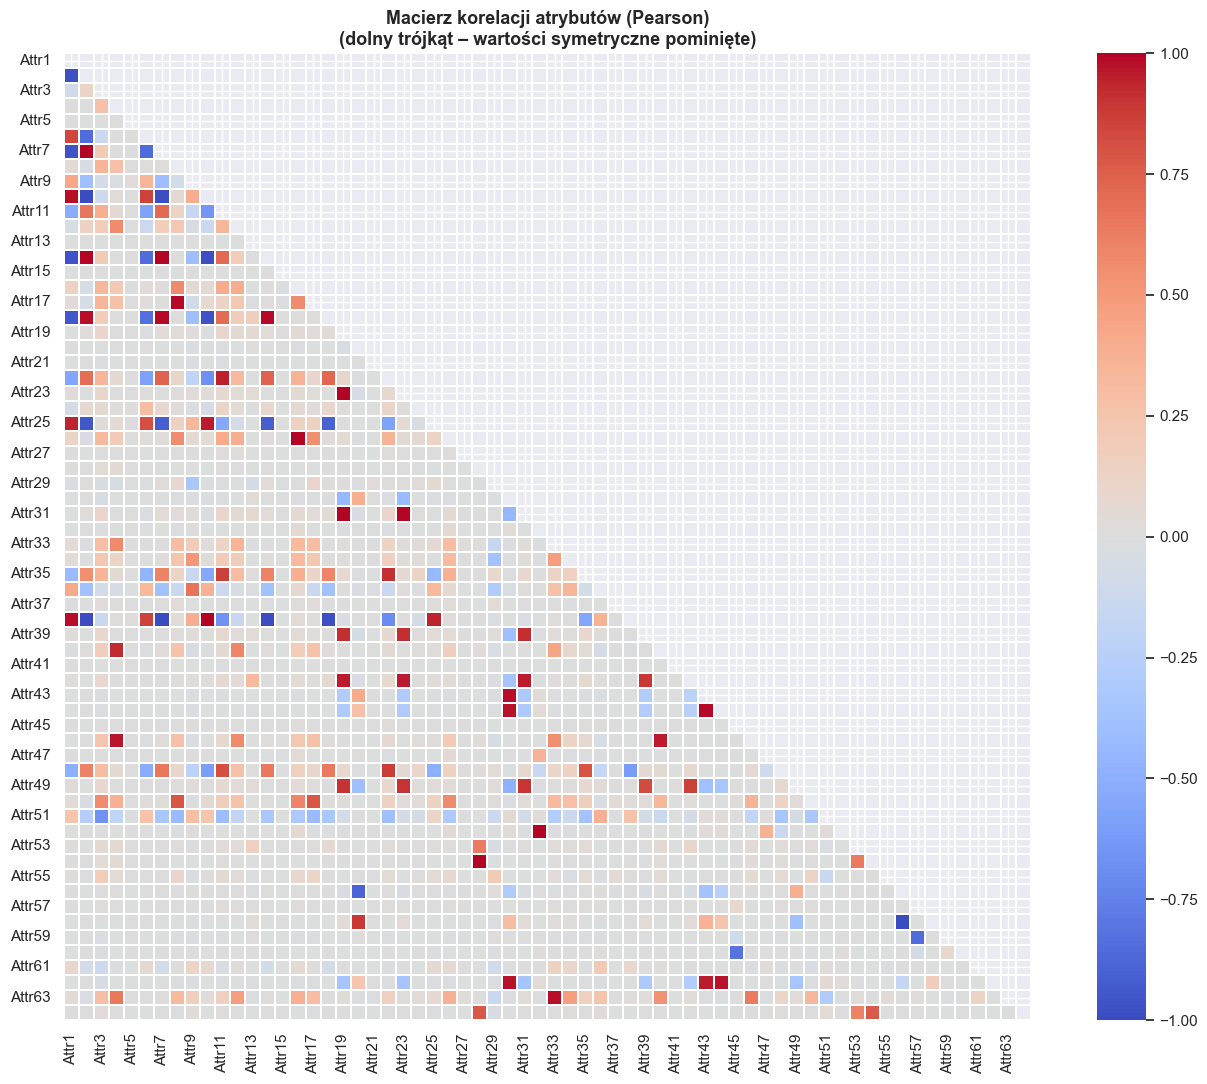


Wniosek: w zbiorze widoczne są grupy silnie skorelowanych atrybutów finansowych.
Wysoka współliniowość między zmiennymi oznacza redundancję informacji,
co uzasadnia zastosowanie PCA – pozwoli ono skompresować skorelowane atrybuty
do mniejszej liczby nieskorelowanych składowych głównych bez istotnej utraty informacji.



In [10]:
# 1.6 Macierz korelacji

corr_matrix = df[features].dropna().corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.3,
    annot=False,
    square=True
)
plt.title(
    'Macierz korelacji atrybutów (Pearson)'
    '\n(dolny trójkąt – wartości symetryczne pominięte)',
    fontsize=13,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

summary = """
Wniosek: w zbiorze widoczne są grupy silnie skorelowanych atrybutów finansowych.
Wysoka współliniowość między zmiennymi oznacza redundancję informacji,
co uzasadnia zastosowanie PCA – pozwoli ono skompresować skorelowane atrybuty
do mniejszej liczby nieskorelowanych składowych głównych bez istotnej utraty informacji.
"""
print(summary)


## Zadanie 2 – Redukcja wymiarów: PCA i t-SNE (2 pkt)


In [11]:
# 2.1 Przygotowanie danych do redukcji wymiarów
# Przed PCA i t-SNE musimy:
# 1. Usunąć/imputować brakujące wartości (algorytmy nie akceptują NaN)
# 2. Dokonać standaryzacji danych (PCA jest wrażliwe na skalę)

X = df[features].copy() # Atrybuty
y = df['class'].copy() # Etykiety klas

# Imputacja – zastępujemy NaN medianą kolumny
imputer = SimpleImputer(strategy='median')
X_imp = imputer.fit_transform(X)

# Standaryzacja – skalujemy dane
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)

print(f'Kształt danych po przygotowaniu: {X_scaled.shape}')
print(f'Czy są NaN: {np.isnan(X_scaled).any()}')

Kształt danych po przygotowaniu: (43405, 64)
Czy są NaN: False


80% wariancji wyjaśnia 17 składowych
90% wariancji wyjaśnia 23 składowych
95% wariancji wyjaśnia 28 składowych


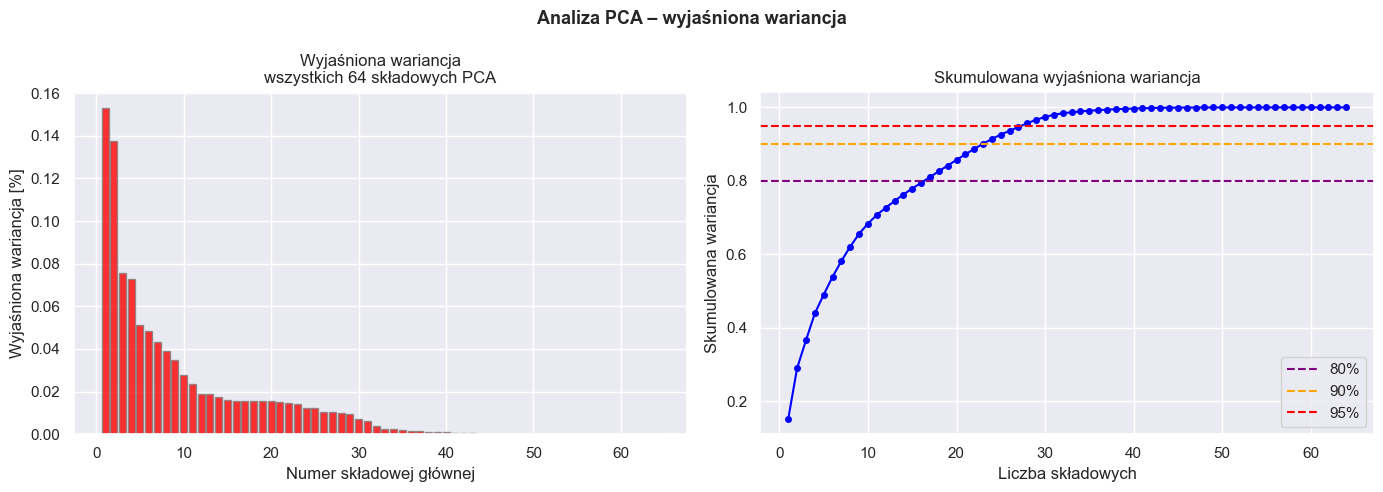


Wniosek: pierwsze składowe główne wyjaśniają znaczną część wariancji zbioru.
Wykres skumulowany pokazuje, ile składowych wystarczy do zachowania
80/90/95% informacji – pozwala to świadomie wybrać liczbę wymiarów
przy dalszej redukcji, zachowując balans między kompresją a utratą informacji.



In [12]:
# 2.2 PCA – wizualizacja i analiza wyjaśnionej wariancji

# PCA z pełną liczbą komponentów
pca_full = PCA(random_state=1)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

for threshold in [0.80, 0.90, 0.95]:
    n = np.searchsorted(cumulative, threshold) + 1
    print(f'{threshold*100:.0f}% wariancji wyjaśnia {n} składowych')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Wykres 1 – wariancja każdej składowej
n_components = len(explained)
axes[0].bar(range(1, n_components + 1), explained,
            color='red', edgecolor='gray', alpha=0.8)
axes[0].set_xlabel('Numer składowej głównej')
axes[0].set_ylabel('Wyjaśniona wariancja [%]')
axes[0].set_title('Wyjaśniona wariancja\nwszystkich 64 składowych PCA')

# Wykres 2 – skumulowana wariancja wszystkich składowych
axes[1].plot(range(1, len(cumulative) + 1), cumulative, 'o-', color='blue', markersize=4)
axes[1].axhline(0.80, color='purple', linestyle='--', label='80%')
axes[1].axhline(0.90, color='orange', linestyle='--', label='90%')
axes[1].axhline(0.95, color='red', linestyle='--', label='95%')
axes[1].set_xlabel('Liczba składowych')
axes[1].set_ylabel('Skumulowana wariancja')
axes[1].set_title('Skumulowana wyjaśniona wariancja')
axes[1].legend()

plt.suptitle('Analiza PCA – wyjaśniona wariancja', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

summary = """
Wniosek: pierwsze składowe główne wyjaśniają znaczną część wariancji zbioru.
Wykres skumulowany pokazuje, ile składowych wystarczy do zachowania
80/90/95% informacji – pozwala to świadomie wybrać liczbę wymiarów
przy dalszej redukcji, zachowując balans między kompresją a utratą informacji.
"""
print(summary)

Wariancja wyjaśniona przez PC1: 15.30%
Wariancja wyjaśniona przez PC2: 13.77%
Łącznie (PC1+PC2): 29.07%


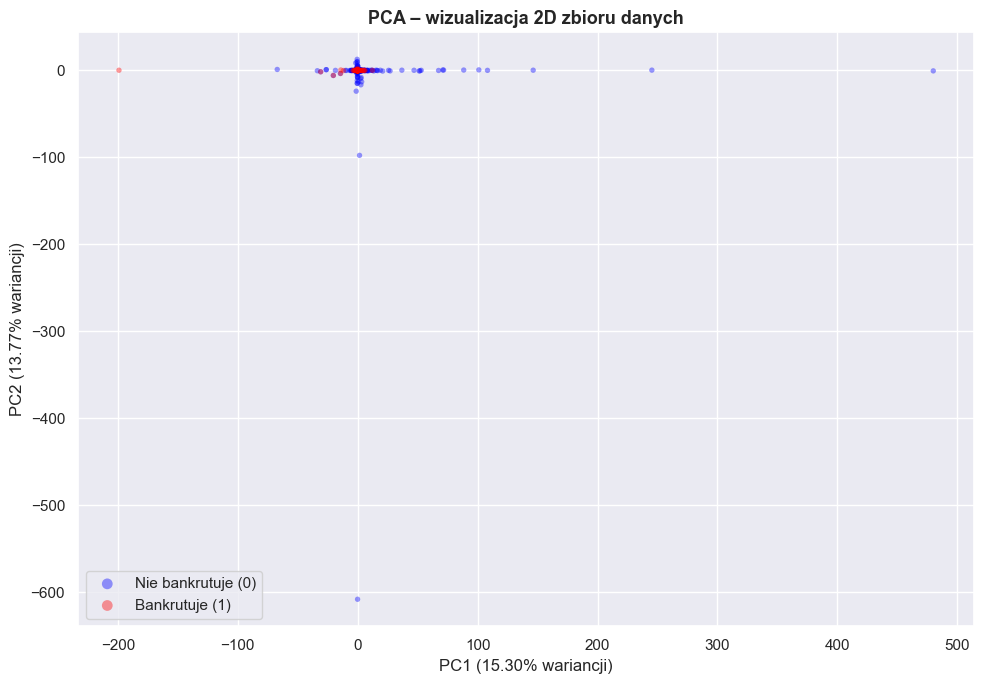


Wniosek: dwie pierwsze składowe główne wyjaśniają łącznie 29.07% wariancji.
Klasy nakładają się na siebie – PCA jako metoda liniowa nie jest w stanie
rozdzielić bankrutujących i nie bankrutująch spółek w przestrzeni 2D.
Wynika to z faktu, że granica decyzyjna między klasami ma charakter nieliniowy.



In [13]:
# 2.3 PCA – wizualizacja 2D

pca_2d = PCA(n_components=2, random_state=1)
X_pca  = pca_2d.fit_transform(X_scaled)
variance1 = pca_2d.explained_variance_ratio_[0]*100
variance2 = pca_2d.explained_variance_ratio_[1]*100
print(f'Wariancja wyjaśniona przez PC1: {variance1:.2f}%')
print(f'Wariancja wyjaśniona przez PC2: {variance2:.2f}%')
print(f'Łącznie (PC1+PC2): {variance1+variance2:.2f}%')

_, ax = plt.subplots(figsize=(10, 7))

colors = {0: 'blue', 1: 'red'}
labels = {0: 'Nie bankrutuje (0)', 1: 'Bankrutuje (1)'}

for cls in [0, 1]:
    mask = y == cls
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=colors[cls], label=labels[cls],
        alpha=0.4, s=15, edgecolors='none'
    )

ax.set_xlabel(f'PC1 ({variance1:.2f}% wariancji)')
ax.set_ylabel(f'PC2 ({variance2:.2f}% wariancji)')
ax.set_title('PCA – wizualizacja 2D zbioru danych', fontsize=13, fontweight='bold')
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()
summary = f"""
Wniosek: dwie pierwsze składowe główne wyjaśniają łącznie {variance1+variance2:.2f}% wariancji.
Klasy nakładają się na siebie – PCA jako metoda liniowa nie jest w stanie
rozdzielić bankrutujących i nie bankrutująch spółek w przestrzeni 2D.
Wynika to z faktu, że granica decyzyjna między klasami ma charakter nieliniowy.
"""
print(summary)

Rozmiar próbki do t-SNE: 10000 rekordów


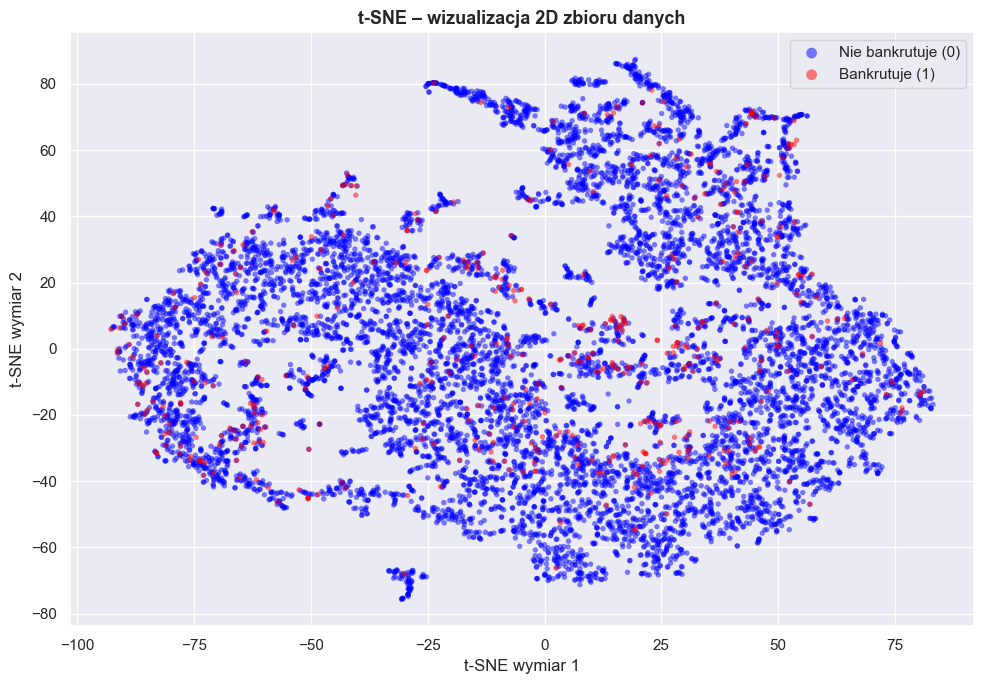


Wniosek: t-SNE ujawnia lokalną strukturę skupisk w danych, której PCA nie wykryło.
Mimo to klasy nie są wyraźnie odseparowane – punkty klasy 1 (bankructwo)
rozrzucone są wśród klasy 0, co odzwierciedla trudność zadania klasyfikacji.
Dominacja klasy 0 (niezbalansowanie) jest wyraźnie widoczna na wykresie.



In [14]:
# 2.4 t-SNE – wizualizacja 2D
sample_size = min(10000, len(X_scaled))
idx_sample  = np.random.RandomState(1).choice(len(X_scaled), sample_size, replace=False)

X_sample = X_scaled[idx_sample]
y_sample = y.values[idx_sample]

print(f'Rozmiar próbki do t-SNE: {sample_size} rekordów')

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=1,
    verbose=0,
)
X_tsne = tsne.fit_transform(X_sample)

# Wizualizacja wyników t-SNE
_, ax = plt.subplots(figsize=(10, 7))

for cls in [0, 1]:
    mask = y_sample == cls
    ax.scatter(
        X_tsne[mask, 0], X_tsne[mask, 1],
        c=colors[cls], label=labels[cls],
        alpha=0.5, s=15, edgecolors='none'
    )

ax.set_xlabel('t-SNE wymiar 1')
ax.set_ylabel('t-SNE wymiar 2')
ax.set_title('t-SNE – wizualizacja 2D zbioru danych', fontsize=13, fontweight='bold')
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

summary = """
Wniosek: t-SNE ujawnia lokalną strukturę skupisk w danych, której PCA nie wykryło.
Mimo to klasy nie są wyraźnie odseparowane – punkty klasy 1 (bankructwo)
rozrzucone są wśród klasy 0, co odzwierciedla trudność zadania klasyfikacji.
Dominacja klasy 0 (niezbalansowanie) jest wyraźnie widoczna na wykresie.
"""
print(summary)

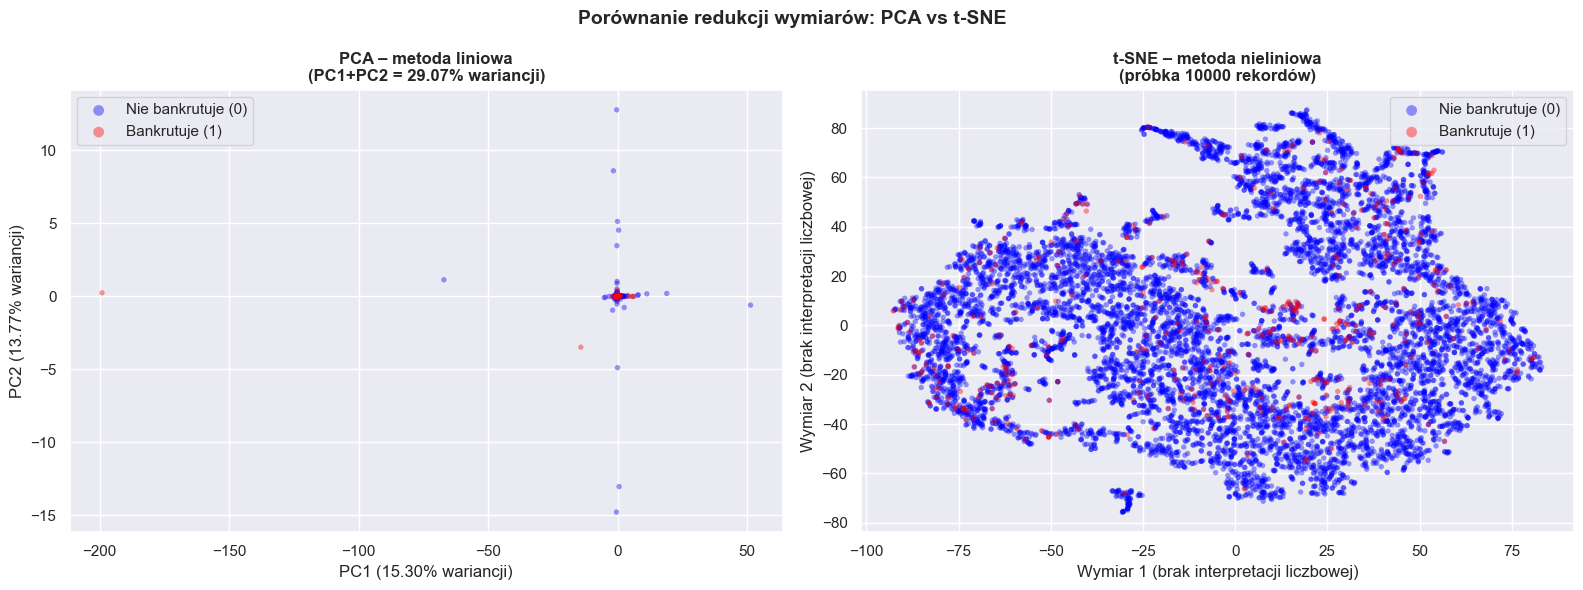


Wnioski: Porównanie PCA vs t-SNE:
- PCA (liniowa): zachowuje globalną strukturę wariancji danych, jest deterministyczna
  i szybka. Dwie pierwsze składowe wyjaśniają jednak niewielki procent wariancji,
  przez co klasy silnie się nakładają – granica decyzyjna ma charakter nieliniowy.
- t-SNE (nieliniowa): lepiej ujawnia lokalne skupiska w danych, punkty klasy 1
  tworzą widoczne zagęszczenia. Osie wykresu nie mają interpretacji liczbowej
  i metody nie można użyć do transformacji nowych danych – służy wyłącznie wizualizacji.
- Wniosek ogólny: żadna z metod nie zapewnia czystej separacji klas, co potwierdza
  trudność zadania. Niezbalansowanie klas (dominacja klasy 0) jest widoczne
  na obu wykresach i będzie wymagało uwagi przy budowie modeli klasyfikacji.



In [29]:
# 2.5 Porównanie PCA vs t-SNE
# Oba wykresy pokazują tę samą próbkę 10000 rekordów
_, axes = plt.subplots(1, 2, figsize=(16, 6))

X_pca_sample = X_pca[idx_sample]

for cls in [0, 1]:
    mask = y_sample == cls
    axes[0].scatter(
        X_pca_sample[mask, 0],
        X_pca_sample[mask, 1],
        c=colors[cls],
        label=labels[cls],
        alpha=0.4,
        s=15,
        edgecolors='none'
    )
    axes[1].scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        c=colors[cls],
        label=labels[cls],
        alpha=0.4,
        s=15,
        edgecolors='none'
    )

axes[0].set_title(f'PCA – metoda liniowa\n(PC1+PC2 = {variance1+variance2:.2f}% wariancji)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({variance1:.2f}% wariancji)')
axes[0].set_ylabel(f'PC2 ({variance2:.2f}% wariancji)')
axes[0].legend(markerscale=2)

axes[1].set_title('t-SNE – metoda nieliniowa\n(próbka 10000 rekordów)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Wymiar 1 (brak interpretacji liczbowej)')
axes[1].set_ylabel('Wymiar 2 (brak interpretacji liczbowej)')
axes[1].legend(markerscale=2)

plt.suptitle('Porównanie redukcji wymiarów: PCA vs t-SNE',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

summary = """
Wnioski: Porównanie PCA vs t-SNE:
- PCA (liniowa): zachowuje globalną strukturę wariancji danych, jest deterministyczna
  i szybka. Dwie pierwsze składowe wyjaśniają jednak niewielki procent wariancji,
  przez co klasy silnie się nakładają – granica decyzyjna ma charakter nieliniowy.
- t-SNE (nieliniowa): lepiej ujawnia lokalne skupiska w danych, punkty klasy 1
  tworzą widoczne zagęszczenia. Osie wykresu nie mają interpretacji liczbowej
  i metody nie można użyć do transformacji nowych danych – służy wyłącznie wizualizacji.
- Wniosek ogólny: żadna z metod nie zapewnia czystej separacji klas, co potwierdza
  trudność zadania. Niezbalansowanie klas (dominacja klasy 0) jest widoczne
  na obu wykresach i będzie wymagało uwagi przy budowie modeli klasyfikacji.
"""
print(summary)

## Zadanie 3 – Preprocessing danych (4 pkt)

In [30]:
# 3.1 Imputacja brakujących danych

X_raw = df[features].copy()
y = df['class'].copy()

print('Przed imputacją')
print(f'Brakujące wartości łącznie: {X_raw.isnull().sum().sum()}')

# Imputacja medianą – odporna na wartości odstające (outliers).
imputer = SimpleImputer(strategy='median')
X_imp = pd.DataFrame(
    imputer.fit_transform(X_raw),
    columns=features,
)

print('\nPo imputacji medianą')
print(f'Brakujące wartości łącznie: {X_imp.isnull().sum().sum()}')
print(f'Kształt: {X_imp.shape}')

Przed imputacją
Brakujące wartości łącznie: 41322

Po imputacji medianą
Brakujące wartości łącznie: 0
Kształt: (43405, 64)


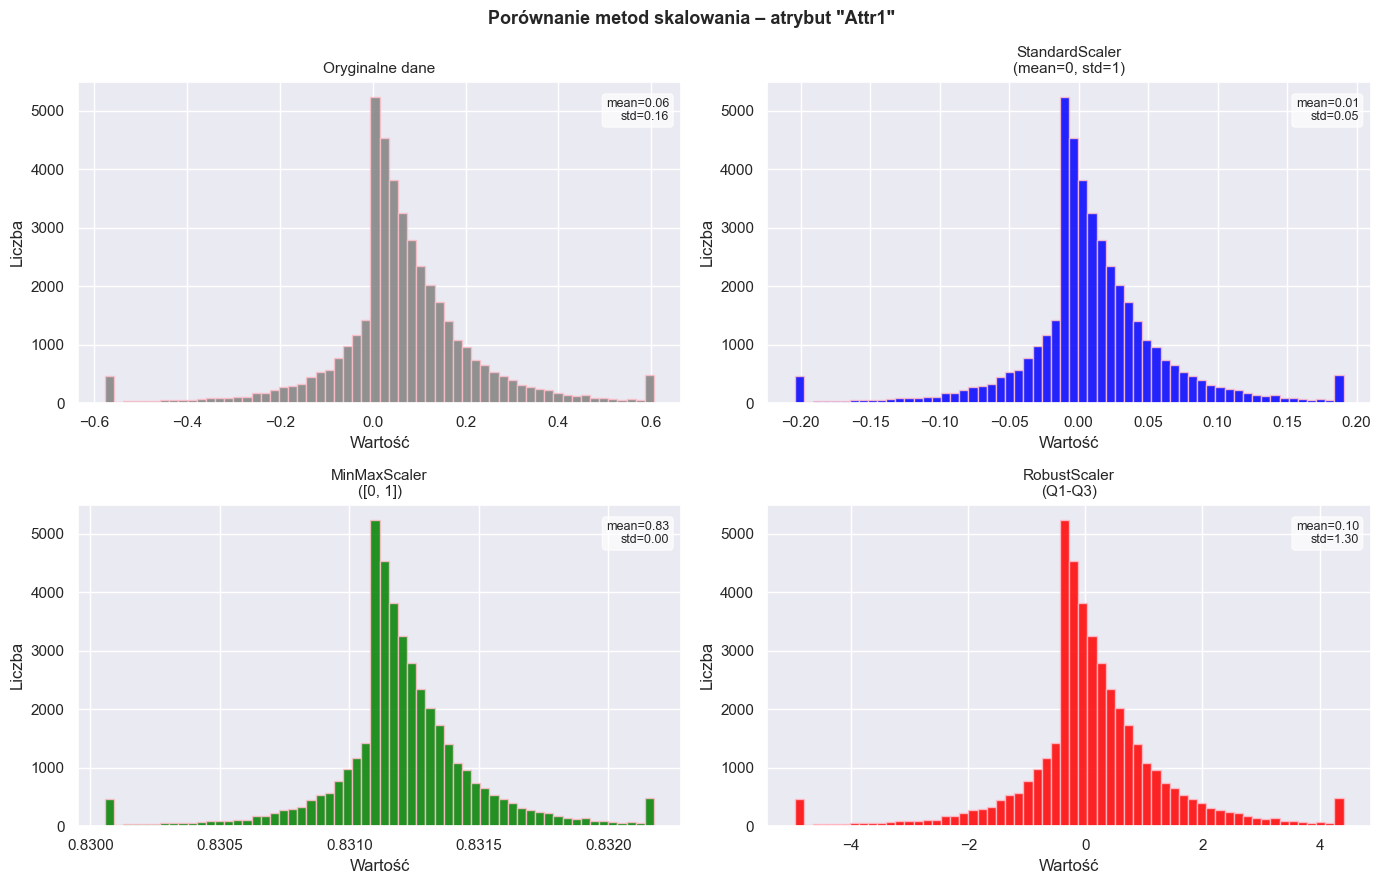


Wniosek: każda metoda skalowania zachowuje kształt rozkładu – zmienia się tylko skala.
* StandardScaler centruje dane do mean=0, std=1, ale jest wrażliwy na outliery.
* MinMaxScaler sprowadza wartości do zakresu [0,1], lecz jest najbardziej
podatny na ekstremalne wartości odstające, które mogą ścisnąć pozostałe dane.
* RobustScaler używa mediany i rozstępu międzykwartylowego (IQR = Q3-Q1),
przez co jest najmniej wrażliwy na outliery.



In [17]:
# 3.2 Porównanie metod skalowania

col_demo = features[0]
data_raw = X_imp[[col_demo]].copy()

std_scaled = StandardScaler().fit_transform(data_raw).flatten()
minmax_scaled = MinMaxScaler().fit_transform(data_raw).flatten()
robust_scaled = RobustScaler().fit_transform(data_raw).flatten()

# Przycinamy na potrzeby czytelności wykresu
def clip_for_display(arr, pct=99):
    lo, hi = np.percentile(arr, 100 - pct), np.percentile(arr, pct)
    return np.clip(arr, lo, hi)

_, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

datasets = [
    (clip_for_display(data_raw.values.flatten()), 'Oryginalne dane', 'gray'),
    (clip_for_display(std_scaled), 'StandardScaler\n(mean=0, std=1)', 'blue'),
    (clip_for_display(minmax_scaled), 'MinMaxScaler\n([0, 1])', 'green'),
    (clip_for_display(robust_scaled), 'RobustScaler\n(Q1-Q3)', 'red'),
]

for ax, (data, title, color) in zip(axes, datasets):
    ax.hist(data, bins=60, color=color, edgecolor='pink', alpha=0.85)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Wartość')
    ax.set_ylabel('Liczba')
    ax.text(0.98, 0.95,
            f'mean={np.mean(data):.2f}\nstd={np.std(data):.2f}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=9, bbox=dict(boxstyle='round', fc='white', alpha=0.7))

plt.suptitle(f'Porównanie metod skalowania – atrybut "{col_demo}"', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

summary = """
Wniosek: każda metoda skalowania zachowuje kształt rozkładu – zmienia się tylko skala.
* StandardScaler centruje dane do mean=0, std=1, ale jest wrażliwy na outliery.
* MinMaxScaler sprowadza wartości do zakresu [0,1], lecz jest najbardziej
podatny na ekstremalne wartości odstające, które mogą ścisnąć pozostałe dane.
* RobustScaler używa mediany i rozstępu międzykwartylowego (IQR = Q3-Q1),
przez co jest najmniej wrażliwy na outliery.
"""
print(summary)


Liczba rekordów zawierających outliery (wg IQR): 39556:91.13% wszystkich rekordów)
Strategia: zamiast usuwać rekordy, stosujemy winsoryzację (capping),
outliery są przycinane do percentyli [1%, 99%], nie usuwane.
Usuwanie mogłoby wyeliminować prawdziwe przypadki bankructwa (klasa 1),
które przyjmują ekstremalne wartości.



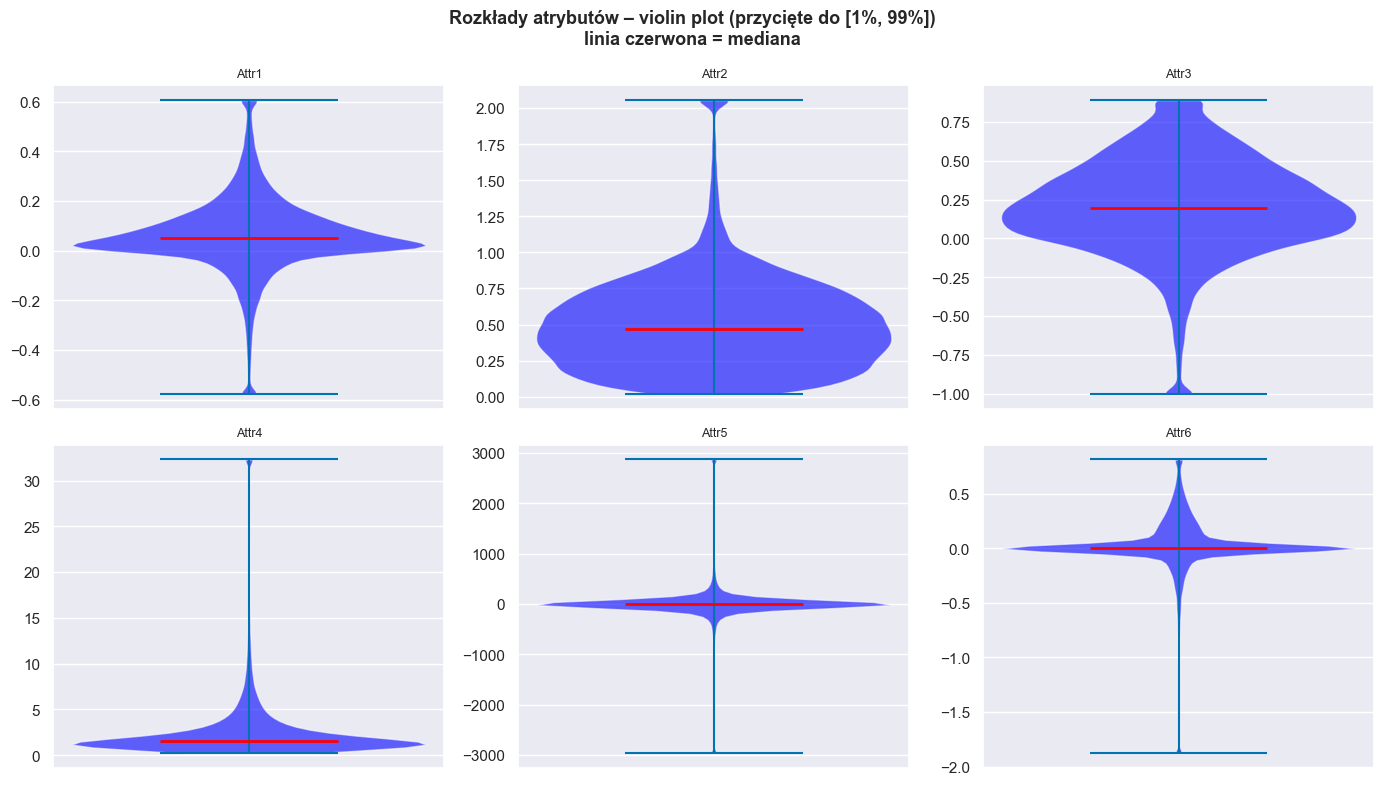

<Figure size 1000x600 with 0 Axes>


Wniosek: Wykresy violin plot ujawniają kształt rozkładu każdego atrybutu.
Większość zmiennych wykazuje silną asymetrię i skupienie wartości
w wąskim zakresie, co potwierdza konieczność winsoryzacji i RobustScaler.



In [18]:
# 3.3 Detekcja outlierów metodą IQR (Interquartile Range) = Q3 - Q1
Q1 = X_imp.quantile(0.25)
Q3 = X_imp.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

is_outlier_iqr = ((X_imp < lower_bound) | (X_imp > upper_bound)).any(axis=1)

summary = f"""
Liczba rekordów zawierających outliery (wg IQR): {is_outlier_iqr.sum()}:{is_outlier_iqr.mean()*100:.2f}% wszystkich rekordów)
Strategia: zamiast usuwać rekordy, stosujemy winsoryzację (capping),
outliery są przycinane do percentyli [1%, 99%], nie usuwane.
Usuwanie mogłoby wyeliminować prawdziwe przypadki bankructwa (klasa 1),
które przyjmują ekstremalne wartości.
"""
print(summary)

selected_cols = features[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(selected_cols):
    col_data = X_imp[col]
    lo = col_data.quantile(0.01)
    hi = col_data.quantile(0.99)
    clipped = col_data.clip(lo, hi)

    # Violin plot – łączy informację o outlierach (jak boxplot) z kształtem rozkładu
    parts = axes[i].violinplot(clipped, vert=True, showmedians=True, showextrema=True)
    for pc in parts['bodies']:
        pc.set_facecolor('blue')
        pc.set_alpha(0.6)
    parts['cmedians'].set_color('red')
    parts['cmedians'].set_linewidth(2)

    axes[i].set_title(col, fontsize=9)
    axes[i].set_xticks([])

plt.suptitle(
    'Rozkłady atrybutów – violin plot (przycięte do [1%, 99%])\n'
    'linia czerwona = mediana',
    fontsize=13,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

summary = """
Wniosek: Wykresy violin plot ujawniają kształt rozkładu każdego atrybutu.
Większość zmiennych wykazuje silną asymetrię i skupienie wartości
w wąskim zakresie, co potwierdza konieczność winsoryzacji i RobustScaler.
"""
print(summary)

In [19]:
# 3.4 Winsoryzacja (Outliers Capping)

x_capping = X_imp.copy()

for col in features:
    p01 = x_capping[col].quantile(0.01)
    p99 = x_capping[col].quantile(0.99)
    x_capping[col] = x_capping[col].clip(lower=p01, upper=p99)

print('Winsoryzacja zakończona (przycięcie do [1%, 99%]).')
print(f'Kształt: {x_capping.shape}')

print('\nPorównanie: min/max przed i po winsoryzacji (5 kolumn):')
comparison = pd.DataFrame({
    'Min (przed)': X_imp[features[:5]].min(),
    'Max (przed)': X_imp[features[:5]].max(),
    'Min (po)':    x_capping[features[:5]].min(),
    'Max (po)':    x_capping[features[:5]].max(),
}).round(3)
print(comparison)

Winsoryzacja zakończona (przycięcie do [1%, 99%]).
Kształt: (43405, 64)

Porównanie: min/max przed i po winsoryzacji (5 kolumn):
        Min (przed)  Max (przed)  Min (po)  Max (po)
Attr1 -4.638900e+02       94.280    -0.577     0.606
Attr2 -4.308700e+02      480.960     0.019     2.056
Attr3 -4.799600e+02       28.336    -1.001     0.890
Attr4 -4.030000e-01    53433.000     0.200    32.301
Attr5 -1.190300e+07  1250100.000 -2969.528  2873.844


In [20]:
# 3.5 Finalne skalowanie danych do modeli

robust_scaler = RobustScaler()
X_final = robust_scaler.fit_transform(x_capping)

print(f'Dane gotowe do modelowania: {X_final.shape}')
print(f'Średnia po skalowaniu (pierwsze 3 kolumny): {X_final[:, :3].mean(axis=0).round(3)}')
print(f'Std po skalowaniu (pierwsze 3 kolumny): {X_final[:, :3].std(axis=0).round(3)}')

Dane gotowe do modelowania: (43405, 64)
Średnia po skalowaniu (pierwsze 3 kolumny): [0.096 0.091 0.005]
Std po skalowaniu (pierwsze 3 kolumny): [1.304 0.8   0.839]


## Zadanie 4 – Przygotowanie podzbiorów treningowych i testowych


In [31]:
# 4 Podział na zbiór treningowy i testowy

X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y.values,
    test_size=0.20,
    stratify=y.values,
    random_state=1,
)

print('Podział danych')
print(f'Zbiór treningowy: {X_train.shape[0]} rekordów ({X_train.shape[0]/len(X_final)*100:.0f}%)')
print(f'Zbiór testowy: {X_test.shape[0]} rekordów  ({X_test.shape[0]/len(X_final)*100:.0f}%)')

print('\nRozkład klas')
for split_name, y_split in [('Treningowy', y_train), ('Testowy', y_test)]:
    unique, counts = np.unique(y_split, return_counts=True)
    for cls, cnt in zip(unique, counts):
        print(f' Zbiór: {split_name}, Klasa {cls}: {cnt} ({cnt/len(y_split)*100:.2f}%)')

Podział danych
Zbiór treningowy: 34724 rekordów (80%)
Zbiór testowy: 8681 rekordów  (20%)

Rozkład klas
 Zbiór: Treningowy, Klasa 0: 33051 (95.18%)
 Zbiór: Treningowy, Klasa 1: 1673 (4.82%)
 Zbiór: Testowy, Klasa 0: 8263 (95.18%)
 Zbiór: Testowy, Klasa 1: 418 (4.82%)


## Zadanie 5 – Modele klasyfikacji (2 pkt)

In [33]:
# 5.1 Random Forest

rf = RandomForestClassifier(
    n_estimators=100, # Liczba drzew decyzyjnych
    max_depth=10, # Maksymalna głębokość drzewa
    class_weight='balanced',
    random_state=1,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf  = rf.predict(X_test)
y_prob_rf  = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf,
                             target_names=['Nie bankrutuje (0)', 'Bankrutuje (1)']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}')

                    precision    recall  f1-score   support

Nie bankrutuje (0)       0.98      0.96      0.97      8263
    Bankrutuje (1)       0.39      0.55      0.46       418

          accuracy                           0.94      8681
         macro avg       0.68      0.75      0.71      8681
      weighted avg       0.95      0.94      0.94      8681

ROC-AUC: 0.9112


In [23]:
# 5.2 Regresja Logistyczna

print('Regresja logistyczna')

lr = LogisticRegression(
    max_iter=40000, # Maksymalna liczba iteracji
    class_weight='balanced',
    solver='lbfgs',
    C=1.0,
)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Nie bankrutuje (0)', 'Bankrutuje (1)']
))
print(f'Roc-auc: {roc_auc_score(y_test, y_prob_lr):.4f}')

Regresja logistyczna
                    precision    recall  f1-score   support

Nie bankrutuje (0)       0.98      0.75      0.85      8263
    Bankrutuje (1)       0.13      0.71      0.21       418

          accuracy                           0.75      8681
         macro avg       0.55      0.73      0.53      8681
      weighted avg       0.94      0.75      0.82      8681

Roc-auc: 0.7867


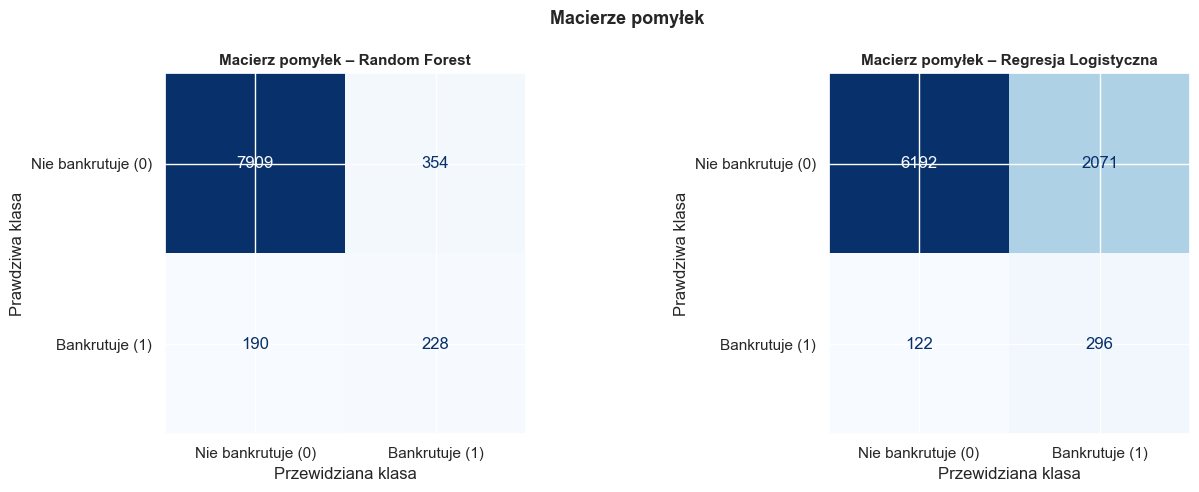


* Macierz pomyłek pozwala na szczegółową analizę działania modelu poprzez pokazanie liczby poprawnych i błędnych
klasyfikacji dla każdej klasy. W przeciwieństwie do miar takich jak accuracy czy F1-score, umożliwia identyfikację
rodzaju popełnianych błędów (np. fałszywie negatywnych), co jest szczególnie istotne w problemach takich jak predykcja bankructwa.
* W badanym modelu widzimy, że model:
** Random Forest posiada lepszą klasyfikację dla klasy dominującej, bardzo dokładnie dopasowywuje klasy 0,
 ale ma problemy z klasą zdominowaną, posiada niską skuteczność że klasa bankrutuje zbankrutowała.
** Logistic Regression - ta klasa miała niższą skuteczność dopasowania klasy dominującej, jednak
w przeciwieństwie do RF klasie tej udało się lepiej przewidzieć wystąpienie klasy zdominowanej.



In [35]:
# 5.3. Macierze pomyłek

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_rf, 'Random Forest'),
    (axes[1], y_pred_lr, 'Regresja Logistyczna')
]:
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Nie bankrutuje (0)', 'Bankrutuje (1)']
    )
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Macierz pomyłek – {title}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Przewidziana klasa')
    ax.set_ylabel('Prawdziwa klasa')

plt.suptitle('Macierze pomyłek', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

summary = """
* Macierz pomyłek pozwala na szczegółową analizę działania modelu poprzez pokazanie liczby poprawnych i błędnych
klasyfikacji dla każdej klasy. W przeciwieństwie do miar takich jak accuracy czy F1-score, umożliwia identyfikację
rodzaju popełnianych błędów (np. fałszywie negatywnych), co jest szczególnie istotne w problemach takich jak predykcja bankructwa.
* W badanym modelu widzimy, że model:
** Random Forest posiada lepszą klasyfikację dla klasy dominującej, bardzo dokładnie dopasowywuje klasy 0,
 ale ma problemy z klasą zdominowaną, posiada niską skuteczność że klasa bankrutuje zbankrutowała.
** Logistic Regression - ta klasa miała niższą skuteczność dopasowania klasy dominującej, jednak
w przeciwieństwie do RF klasie tej udało się lepiej przewidzieć wystąpienie klasy zdominowanej.
"""
print(summary)

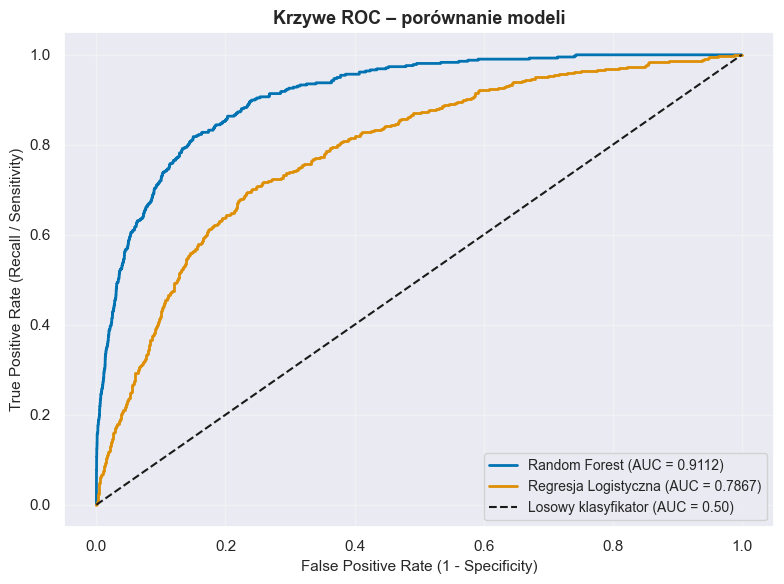


Wnioski:
* Na podstawie analizy krzywych ROC można porównać jakość działania modeli Random Forest oraz Logistic Regression.
Krzywa ROC przedstawia zależność pomiędzy czułością (True Positive Rate)
a odsetkiem fałszywie pozytywnych klasyfikacji (False Positive Rate).

* Model, którego krzywa ROC znajduje się bliżej lewego górnego rogu wykresu,
 charakteryzuje się lepszą zdolnością rozróżniania klas. Dodatkowo wartość AUC (Area Under Curve)
 pozwala ilościowo ocenić jakość modelu – im wyższa, tym lepszy model.

* W analizowanym przypadku model o wyższej wartości AUC (Random Forest) osiąga lepsze wyniki klasyfikacji
 i lepiej radzi sobie z rozróżnianiem klas. Oznacza to, że jest bardziej skuteczny w identyfikacji przypadków
  pozytywnych (np. bankructwa) przy jednoczesnym ograniczeniu liczby błędnych alarmów.

* Krzywa ROC stanowi ważne narzędzie oceny modeli, ponieważ uwzględnia różne progi decyzyjne i daje pełniejszy obraz
działania modelu niż pojedyncze miary, takie jak accuracy czy F

In [25]:
# 5.4 Krzywe ROC (receiver operating characteristic curve)

_, ax = plt.subplots(figsize=(8, 6))

for name, y_prob in [('Random Forest', y_prob_rf), ('Regresja Logistyczna', y_prob_lr)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_score:.4f})') # The Area Under the Curve (AUC) score

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Losowy klasyfikator (AUC = 0.50)')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax.set_title('Krzywe ROC – porównanie modeli', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

summary = """
Wnioski:
* Na podstawie analizy krzywych ROC można porównać jakość działania modeli Random Forest oraz Logistic Regression.
Krzywa ROC przedstawia zależność pomiędzy czułością (True Positive Rate)
a odsetkiem fałszywie pozytywnych klasyfikacji (False Positive Rate).

* Model, którego krzywa ROC znajduje się bliżej lewego górnego rogu wykresu,
 charakteryzuje się lepszą zdolnością rozróżniania klas. Dodatkowo wartość AUC (Area Under Curve)
 pozwala ilościowo ocenić jakość modelu – im wyższa, tym lepszy model.

* W analizowanym przypadku model o wyższej wartości AUC (Random Forest) osiąga lepsze wyniki klasyfikacji
 i lepiej radzi sobie z rozróżnianiem klas. Oznacza to, że jest bardziej skuteczny w identyfikacji przypadków
  pozytywnych (np. bankructwa) przy jednoczesnym ograniczeniu liczby błędnych alarmów.

* Krzywa ROC stanowi ważne narzędzie oceny modeli, ponieważ uwzględnia różne progi decyzyjne i daje pełniejszy obraz
działania modelu niż pojedyncze miary, takie jak accuracy czy F1-score.
"""
print(summary)

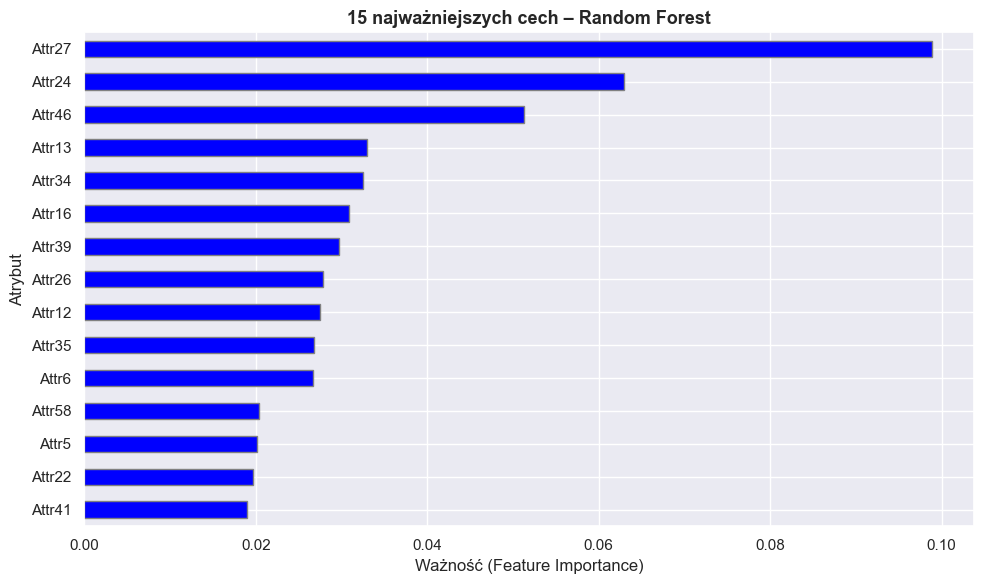

In [26]:
# 5.5  Ważność cech (Random Forest)
importances = pd.Series(rf.feature_importances_, index=features)
top_features = importances.nlargest(15)

_, ax = plt.subplots(figsize=(10, 6))
top_features.sort_values().plot.barh(ax=ax, color='blue', edgecolor='gray')
ax.set_title('15 najważniejszych cech – Random Forest', fontsize=13, fontweight='bold')
ax.set_xlabel('Ważność (Feature Importance)')
ax.set_ylabel('Atrybut')
plt.tight_layout()
plt.show()

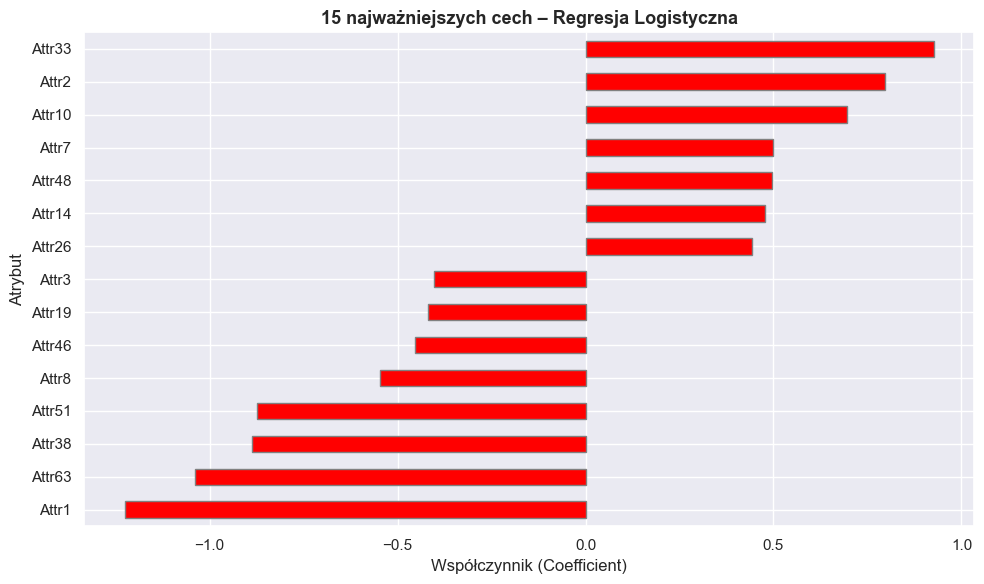


Wniosek:
Analiza ważności cech wskazuje, że tylko niewielka liczba atrybutów ma istotny wpływ na predykcję modelu.
W modelu Random Forest ważność cech wynika z ich wpływu na podziały drzew decyzyjnych,
natomiast w regresji logistycznej współczynniki określają kierunek i siłę wpływu cechy na wynik klasyfikacji.
Zauważalne jest, że niektóre cechy mają zdecydowanie większe znaczenie niż pozostałe,
co może sugerować możliwość redukcji wymiarowości danych bez istotnej utraty jakości modelu.



In [27]:
# 5.6 Ważność cech (Logistic Regression)

coef = pd.Series(lr.coef_[0], index=features)

top_lr = coef.abs().nlargest(15)

_, ax = plt.subplots(figsize=(10, 6))
coef[top_lr.index].sort_values().plot.barh(ax=ax, color="red", edgecolor='gray')

ax.set_title('15 najważniejszych cech – Regresja Logistyczna', fontsize=13, fontweight='bold')
ax.set_xlabel('Współczynnik (Coefficient)')
ax.set_ylabel('Atrybut')

plt.tight_layout()
plt.show()

summary = """
Wniosek:
Analiza ważności cech wskazuje, że tylko niewielka liczba atrybutów ma istotny wpływ na predykcję modelu.
W modelu Random Forest ważność cech wynika z ich wpływu na podziały drzew decyzyjnych,
natomiast w regresji logistycznej współczynniki określają kierunek i siłę wpływu cechy na wynik klasyfikacji.
Zauważalne jest, że niektóre cechy mają zdecydowanie większe znaczenie niż pozostałe,
co może sugerować możliwość redukcji wymiarowości danych bez istotnej utraty jakości modelu.
"""
print(summary)

In [28]:
# 5.7 Podsumowanie wyników

from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

results = {}
for name, y_pred, y_prob in [
    ('Random Forest', y_pred_rf, y_prob_rf),
    ('Logisitic Regression', y_pred_lr, y_prob_lr)
]:
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }

results_df = pd.DataFrame(results).T.round(4)
print('Porównanie modeli')
print(results_df.to_string())
summary = """
Wnioski

Na podstawie uzyskanych wyników można stwierdzić, że oba modele są w stanie wykrywać przypadki bankructwa,
jednak różnią się istotnie jakością i charakterystyką predykcji.

Model Random Forest osiągnął bardzo wysoką dokładność oraz wysoką wartość ROC-AUC (0.91),
co świadczy o bardzo dobrej zdolności rozróżniania klas. Dodatkowo uzyskane wartości Precision i Recall
wskazują, że model zachowuje względną równowagę pomiędzy wykrywaniem bankructw a ograniczaniem liczby
fałszywych alarmów. Najwyższy F1-score spośród analizowanych modeli potwierdza jego ogólnie najlepszą skuteczność.

Regresja logistyczna osiągnęła niższą dokładność oraz niższy F1-score, jednak charakteryzuje się bardzo wysoką czułością (Recall = 0.71).
Oznacza to, że model dobrze wykrywa przypadki bankructwa, ale kosztem dużej liczby błędnych klasyfikacji (niskia  wartość Precision).
Taki model może być przydatny w sytuacjach, gdzie ważniejsze jest wykrycie jak największej liczby zagrożonych firm,
nawet kosztem większej liczby fałszywych alarmów.

Wysokie wartości ROC-AUC dla obu modeli (szczególnie Random Forest) wskazują, że modele uczą się istotnych zależności w danych
i działają znacznie lepiej niż klasyfikator losowy.

Podsumowując, model Random Forest jest lepszym wyborem ogólnym,
natomiast regresja logistyczna może być preferowana w zadaniach wymagających maksymalizacji wykrywalności klasy pozytywnej.
"""
print(summary)

Porównanie modeli
                      Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest           0.9373     0.3918  0.5455    0.4560   0.9112
Logisitic Regression    0.7474     0.1251  0.7081    0.2126   0.7867

Wnioski

Na podstawie uzyskanych wyników można stwierdzić, że oba modele są w stanie wykrywać przypadki bankructwa,
jednak różnią się istotnie jakością i charakterystyką predykcji.

Model Random Forest osiągnął bardzo wysoką dokładność oraz wysoką wartość ROC-AUC (0.91),
co świadczy o bardzo dobrej zdolności rozróżniania klas. Dodatkowo uzyskane wartości Precision i Recall
wskazują, że model zachowuje względną równowagę pomiędzy wykrywaniem bankructw a ograniczaniem liczby
fałszywych alarmów. Najwyższy F1-score spośród analizowanych modeli potwierdza jego ogólnie najlepszą skuteczność.

Regresja logistyczna osiągnęła niższą dokładność oraz niższy F1-score, jednak charakteryzuje się bardzo wysoką czułością (Recall = 0.71).
Oznacza to, że model dobrze wykrywa przypa

## Pytania dodatkowe

### 1. Na czym polega metoda PCA?
PCA (Principal Component Analysis) to **liniowa** technika redukcji wymiarów. Wyznacza nowe osie układu współrzędnych – główne składowe – które są ortogonalne (prostopadłe) i uszeregowane według malejącej wariancji wyjaśnianych danych. Pierwsza składowa wyjaśnia największą część wariancji, kolejne – coraz mniejszą. Dane rzutujemy na kilka pierwszych składowych, tracąc minimalną ilość informacji.

### 2. Na czym polega metoda t-SNE? Jaka jest fundamentalna różnica względem PCA?
t-SNE (t-distributed Stochastic Neighbor Embedding) to **nieliniowa** metoda redukcji wymiarów do wizualizacji. Modeluje podobieństwa między punktami jako rozkłady prawdopodobieństwa i minimalizuje różnicę między tymi rozkładami w przestrzeni wysokowymiarowej i niskowymiarowej.  
**Kluczowa różnica:** PCA jest liniowa, deterministyczna i zachowuje globalną strukturę danych. t-SNE jest nieliniowa, stochastyczna i zachowuje lokalne podobieństwa (skupiska), lecz nie nadaje się do rekonstrukcji oryginalnych danych.

### 3. Na czym polega standaryzacja i normalizacja? Jakie są różnice?
- **Standaryzacja (StandardScaler):** Przekształca dane do rozkładu $N(0, 1)$. Odejmuje średnią i dzieli przez odchylenie standardowe. Nie ogranicza zakresu wartości. Polecana dla PCA, SVM, regresji logistycznej.
- **Normalizacja (MinMaxScaler):** Skaluje dane do zakresu $[0, 1]$ lub $[-1, 1]$. Wrażliwa na outliery. Polecana dla sieci neuronowych, k-NN.
- **RobustScaler:** Używa mediany i IQR zamiast średniej i std – odporny na outliery.

### 4. Na czym polega wybrana metoda detekcji outlierów (IQR)?
Metoda IQR uznaje punkt za outliery, jeśli leży poza przedziałem $[Q_1 - 1.5 \cdot IQR,\ Q_3 + 1.5 \cdot IQR]$.  
Wpływ na podział: Outliery usunięte przed podziałem nie trafiają ani do zbioru treningowego, ani testowego. Jeśli usuwamy je po podziale – musimy uważać, by nie "zaglądać" do zbioru testowego (data leakage).

### 5. Na czym polegają wybrane metody klasyfikacji?
- **Random Forest:** Zbiór drzew decyzyjnych, każde uczone na losowej próbce danych i losowym podzbiorze cech. Wynik to głosowanie większościowe.
- **Regresja Logistyczna:** Liniowy model klasyfikacji modelujący prawdopodobieństwo klasy przez funkcję sigmoid. Uczy się wag ($w$) minimalizując entropię krzyżową.